# k-means clustering notebook
Run notebooks in the following order:\
`preprocessing.ipynb -> imputation.R -> dimensionality_reduction.R -> kmeans_clustering.ipynb`

In [1]:
# Update path and working directory with project root
import os
import sys
from pathlib import Path

project_path = next(path for path in [Path(os.getcwd()), *Path(os.getcwd()).parents] if path.stem == "esa_consulting")
os.chdir(project_path)
sys.path.insert(0, str(project_path))

In [2]:
# Imports
from pathlib import Path
from typing import cast

import numpy as np
import pandas as pd
from gapstat import gapstat_score
from sklearn.cluster import KMeans
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV

from utils.clustering_utils import (
    cluster_summaries,
    predict_clustering_labels,
    print_cluster_stability,
    print_cluster_statistics,
    print_clustering_info,
)
from utils.misc_utils import turn_cats_to_continuous
from utils.plotting_utils import make_plot_cv
from utils.saving_utils import DatasetBundle, save_plot

pd.options.mode.copy_on_write = True
pd.options.future.infer_string = True

In [3]:
# Load data
data_discov_full = DatasetBundle.load(Path("data/preprocessed/data_discov_full"))
data_discov_full.meta = cast(pd.DataFrame, data_discov_full.meta)
data_discov_full.na = cast(pd.DataFrame, data_discov_full.na)
data_valid_full = DatasetBundle.load(Path("data/preprocessed/data_valid_full"))
data_valid_full.meta = cast(pd.DataFrame, data_valid_full.meta)
data_valid_full.na = cast(pd.DataFrame, data_valid_full.na)

data_discov_mfa = pd.read_parquet(Path("data/dim_red/data_discov_mfa.parquet"))
data_valid_mfa = pd.read_parquet(Path("data/dim_red/data_valid_mfa.parquet"))

# Set outputs folder
outputs_folder = "outputs/kmeans_clustering"

Best parameters after cross-validation: {'n_clusters': 99}


/Users/aginatore/Desktop/Consulting/esa_consulting/.venv/lib/python3.12/site-packages/plotnine/guides/guides.py:211: PlotnineWarning: Cannot generate legend for the 'color' aesthetic. Make sure you have mapped a variable to it


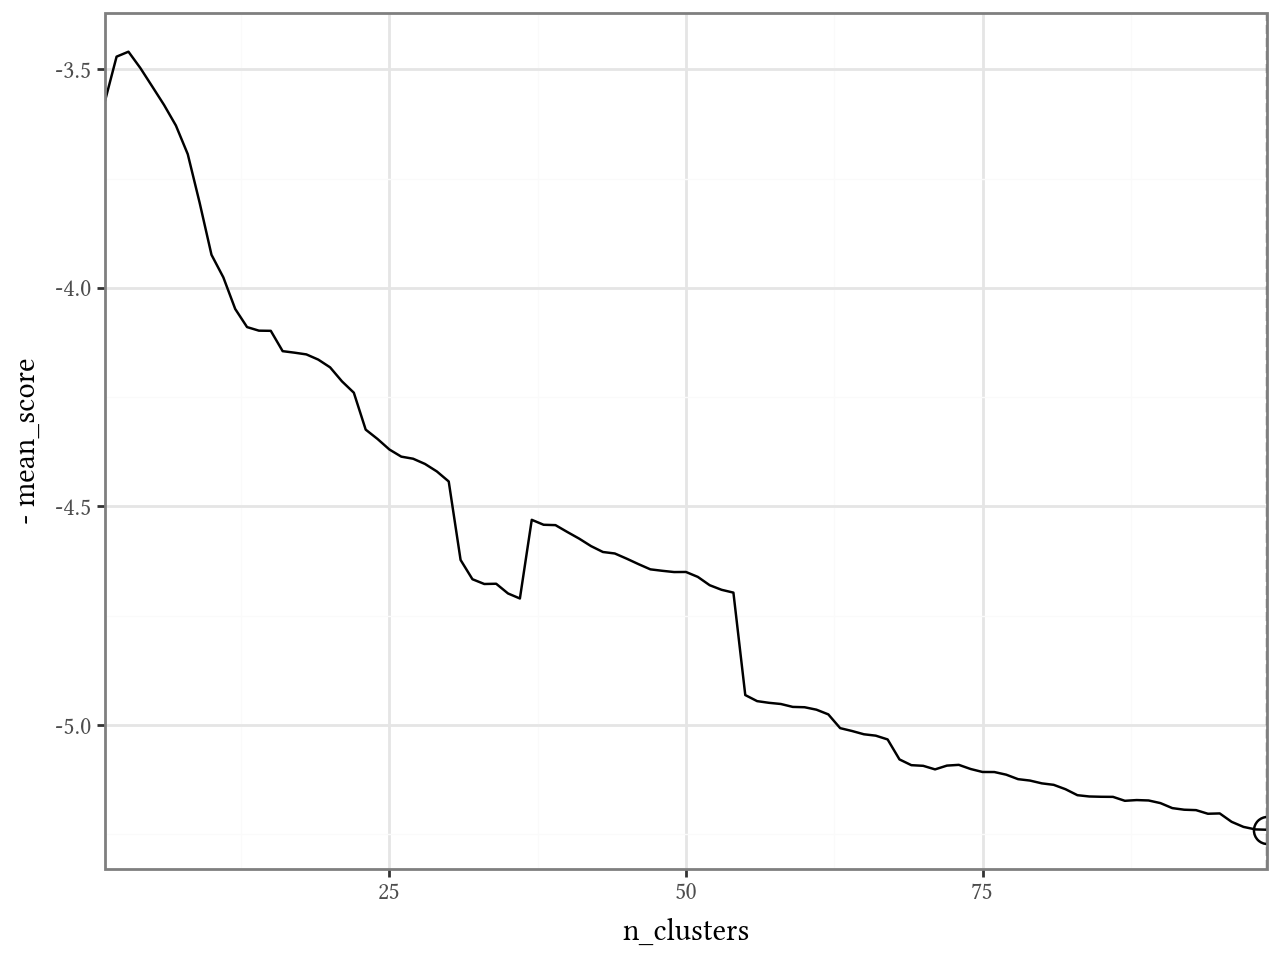

Saved file to outputs/kmeans_clustering/plot_cv.png.


In [4]:
# Set up models
def gapstat_for_cv(estimator: KMeans, X: np.typing.NDArray | pd.DataFrame):
    y_pred = estimator.predict(X)
    return gapstat_score(X, y_pred)


gapstat_scorer = make_scorer(gapstat_for_cv, X=data_discov_mfa, greater_is_better=True)

param_grid = [{"n_clusters": range(1, 100)}]
kmeans_discov = KMeans(random_state=np.random.RandomState(np.random.default_rng(34673).bit_generator))
grid_search_discov = GridSearchCV(kmeans_discov, param_grid=param_grid, scoring=gapstat_for_cv, n_jobs=-1, refit=True)

kmeans_valid = KMeans(random_state=np.random.RandomState(np.random.default_rng(836).bit_generator))

# Fit models
grid_search_discov.fit(data_discov_mfa)
print(f"Best parameters after cross-validation: {grid_search_discov.best_params_}")
plot_cv = make_plot_cv(grid_search_discov)
plot_cv.show()
save_plot(plot_cv, Path(outputs_folder, "plot_cv.png"), dpi=150)

kmeans_valid.set_params(**grid_search_discov.best_params_)
kmeans_valid.fit(data_valid_mfa)

model_discov = grid_search_discov.best_estimator_
model_valid = kmeans_valid

In [5]:
# Apply models to predict labels
labels_discov = predict_clustering_labels(model_discov, data_discov_mfa)
labels_valid = predict_clustering_labels(model_valid, data_valid_mfa)

# Save predictions
pd.DataFrame({"label": labels_discov}).to_parquet(Path(outputs_folder, "cluster_pred_discov.parquet"), index=False)
pd.DataFrame({"label": labels_valid}).to_parquet(Path(outputs_folder, "cluster_pred_valid.parquet"), index=False)

### Display model information

In [6]:
# Print information about clusterings
print("Discovery:    ", end="")
print_clustering_info(labels_discov)
print("Validation:   ", end="")
print_clustering_info(labels_valid)

Discovery:    99 clusters, 0.00% outliers
Percentage in clusters: {'0': 17.20430107526882, '1': 9.960384833050368, '2': 0.06791171477079797, '3': 0.06791171477079797, '4': 0.4527447651386531, '5': 0.011318619128466328, '6': 1.0299943406904357, '7': 0.03395585738539898, '8': 0.04527447651386531, '9': 0.38483305036785515, '10': 1.5732880588568194, '11': 14.91794001131862, '12': 0.06791171477079797, '13': 0.11318619128466327, '14': 1.2903225806451613, '15': 0.1245048104131296, '16': 1.1658177702320316, '17': 0.011318619128466328, '18': 0.011318619128466328, '19': 2.2184493491794, '20': 0.07923033389926429, '21': 0.06791171477079797, '22': 0.03395585738539898, '23': 0.7130730050933786, '24': 0.03395585738539898, '25': 0.03395585738539898, '26': 0.14714204867006225, '27': 0.3395585738539898, '28': 0.2942840973401245, '29': 0.04527447651386531, '30': 0.26032823995472554, '31': 0.13582342954159593, '32': 0.03395585738539898, '33': 0.2942840973401245, '34': 0.011318619128466328, '35': 0.011318

### Get cluster summaries

In [7]:
treat_cat_as_continuous = data_discov_full.meta.loc[lambda x: x["type"].isin(["binary", "ordinal"]), "name"]
data_discov_cont = turn_cats_to_continuous(data_discov_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)
data_valid_cont = turn_cats_to_continuous(data_valid_full.data, treat_cat_as_continuous).select_dtypes(
    exclude="category"
)

In [8]:
# Interpretation of continuous, binary, and ordinal variables
cluster_discov_summaries = cluster_summaries(data_discov_cont, labels_discov, agg_func=["mean", "std"])  # "min", "max"
cluster_discov_summaries

zeit         wichtn                 ges                alter  \
        mean  std      mean       std      mean       std       mean   
cluster                                                                
0        0.0  0.0  1.043736  0.866060  0.646711  0.478149  38.068421   
1        0.0  0.0  0.913311  0.759972  0.479545  0.499866  39.222727   
2        0.0  0.0  0.568633  0.141197  0.833333  0.408248  23.833333   
3        0.0  0.0  0.707628  0.274633  0.666667  0.516398  25.333333   
4        0.0  0.0  1.329795  1.094817  0.525000  0.505736  44.250000   
...      ...  ...       ...       ...       ...       ...        ...   
94       0.0  0.0  0.964163  0.568444  0.518987  0.502832  41.455696   
95       0.0  NaN  0.941501       NaN  0.000000       NaN  50.000000   
96       0.0  0.0  0.784447  0.764075  0.185185  0.395847  29.111111   
97       0.0  0.0  1.880266  1.324302  0.714286  0.487950  47.857143   
98       0.0  0.0  0.624196  0.601591  0.428571  0.534522  25.285714   

                        altq            ...  schm_kat            schl_kat  \
               std      mean       std  ...      mean       std      mean   
cluster                                 ...                                 
0        14.068975  3.093421  1.786264  ...  0.470395  0.670387  0.000658   
1        14.208041  3.227273  1.769591  ...  0.676136  0.695098  0.001136   
2         1.722401  1.333333  0.516398  ...  1.500000  0.547723  0.000000   
3         3.326660  1.666667  0.816497  ...  0.833333  0.752773  0.666667   
4        12.929295  3.775000  1.510434  ...  2.000000  1.109400  0.000000   
...            ...       ...       ...  ...       ...       ...       ...   
94       14.414022  3.443038  1.707801  ...  1.620253  1.029112  0.025316   
95             NaN  5.000000       NaN  ...  2.000000       NaN  2.000000   
96       12.096832  1.703704  1.771892  ...  0.592593  0.747265  0.000000   
97        9.209209  4.285714  0.951190  ...  2.000000  1.414214  2.142857   
98        9.232448  1.142857  1.463850  ...  0.714286  0.755929  0.142857   

                    ber_kat            depr_kat            neur_kat            
              std      mean       std      mean       std      mean       std  
cluster                                                                        
0        0.025649  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
1        0.033710  0.000000  0.000000  0.001136  0.033710  0.000000  0.000000  
2        0.000000  0.000000  0.000000  0.500000  1.224745  0.000000  0.000000  
3        0.816497  0.166667  0.408248  0.000000  0.000000  0.000000  0.000000  
4        0.000000  0.000000  0.000000  0.975000  1.423025  0.150000  0.662164  
...           ...       ...       ...       ...       ...       ...       ...  
94       0.158088  0.000000  0.000000  1.253165  1.489005  0.000000  0.000000  
95            NaN  0.000000       NaN  0.000000       NaN  0.000000       NaN  
96       0.000000  0.000000  0.000000  0.037037  0.192450  0.000000  0.000000  
97       1.463850  2.571429  1.133893  1.714286  1.603567  1.285714  1.603567  
98       0.377964  0.142857  0.377964  0.000000  0.000000  0.000000  0.000000  

[99 rows x 214 columns]

In [9]:
# Interpretation of continuous, binary, and ordinal variables
cluster_valid_summaries = cluster_summaries(data_valid_cont, labels_valid, agg_func=["mean", "std"])  # "min", "max"
cluster_valid_summaries

zeit         wichtn                 ges                alter  \
        mean  std      mean       std      mean       std       mean   
cluster                                                                
0        1.0  0.0  1.134812  1.031025  0.500000  0.508001  32.781250   
1        1.0  0.0  1.003673  0.846442  0.628713  0.484349  42.143564   
2        1.0  0.0  0.920260  0.714225  0.421769  0.494403  39.283447   
3        1.0  0.0  0.693471  0.428683  0.318182  0.469340  28.666667   
4        1.0  0.0  1.006664  1.201367  0.549708  0.498984  30.719298   
...      ...  ...       ...       ...       ...       ...        ...   
94       1.0  0.0  0.728064  0.659866  0.354430  0.479861  28.601266   
95       1.0  0.0  0.821580  0.367190  0.222222  0.427793  29.777778   
96       1.0  NaN  0.496090       NaN  1.000000       NaN  51.000000   
97       1.0  0.0  0.986976  0.716172  0.766667  0.423541  40.955556   
98       1.0  0.0  1.081990  0.673370  0.454545  0.522233  40.272727   

                        altq            ...  schm_kat            schl_kat  \
               std      mean       std  ...      mean       std      mean   
cluster                                 ...                                 
0        12.935907  2.312500  1.821688  ...  1.250000  0.762001  0.000000   
1        13.391324  3.594059  1.676161  ...  1.811881  0.610242  0.054455   
2        14.428473  3.244898  1.822555  ...  0.126984  0.395684  0.004535   
3        11.703166  1.848485  1.638408  ...  0.590909  0.764144  0.030303   
4        12.032927  2.146199  1.710427  ...  0.269006  0.540293  0.005848   
...            ...       ...       ...  ...       ...       ...       ...   
94       11.420699  1.791139  1.655155  ...  0.272152  0.500302  0.006329   
95        8.142521  2.166667  1.248529  ...  0.222222  0.427793  0.000000   
96             NaN  5.000000       NaN  ...  1.000000       NaN  0.000000   
97       12.689268  3.500000  1.529651  ...  0.988889  0.307545  0.008333   
98       15.723173  3.272727  2.004540  ...  2.000000  0.894427  1.727273   

                    ber_kat            depr_kat            neur_kat            
              std      mean       std      mean       std      mean       std  
cluster                                                                        
0        0.000000  0.000000  0.000000  0.093750  0.530330  0.000000  0.000000  
1        0.348422  0.000000  0.000000  0.252475  0.822941  0.014851  0.211079  
2        0.067267  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
3        0.172733  0.000000  0.000000  0.060606  0.387449  0.000000  0.000000  
4        0.076472  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
...           ...       ...       ...       ...       ...       ...       ...  
94       0.079556  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
95       0.000000  0.000000  0.000000  0.333333  0.970143  0.000000  0.000000  
96            NaN  0.000000       NaN  0.000000       NaN  0.000000       NaN  
97       0.117720  0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  
98       1.190874  1.636364  1.026911  2.454545  1.035725  1.818182  1.401298  

[99 rows x 214 columns]

### Compare clusterings
We are dealing with _inferential clustering_, because we are clustering individuals and not variables.\
Method-based validation: The same clustering method is applied to the validation data, and the results are compared between clusterings.\
Result-based validation: The trained cluster algorithm is applied to the validation data, and the results are compared between datasets.\
Cluster stability: The results from the trained and transferred clusterings from the method- and result-based validation steps are compared.

In [10]:
# Compare clusterings
print_cluster_statistics(
    cluster_labels_list=[labels_discov, labels_valid],
    datas=[data_discov_mfa, data_valid_mfa],
    labels=["discovery", "validation"],
)

Comparison between ['discovery', 'validation']:

Discovery:   99 clusters, 0.00% outliers
Percentage in clusters: {'0': 17.20430107526882, '46': 16.842105263157894, '11': 14.91794001131862, '1': 9.960384833050368, '39': 3.6106395019807587, '49': 3.191850594227504, '76': 3.033389926428976, '19': 2.2184493491794, '80': 2.1958121109224673, '50': 2.014714204867006, '63': 1.8449349179400114, '10': 1.5732880588568194, '67': 1.3355970571590265, '93': 1.3016411997736277, '14': 1.2903225806451613, '47': 1.245048104131296, '16': 1.1658177702320316, '59': 1.1318619128466327, '42': 1.1092246745897, '6': 1.0299943406904357, '94': 0.89417091114884, '36': 0.8149405772495755, '23': 0.7130730050933786, '86': 0.622524052065648, '58': 0.5432937181663837, '54': 0.5319750990379174, '45': 0.4753820033955857, '4': 0.4527447651386531, '9': 0.38483305036785515, '83': 0.37351443123938877, '87': 0.3508771929824561, '69': 0.3508771929824561, '27': 0.3395585738539898, '44': 0.30560271646859083, '96': 0.30560271646